# Ways to run and post-process

<!-- index:description -->
Run an existing OpenMC model, continue a simulation with a tighter
convergence criterion, and retrieve tally results directly.
<!-- /index:description -->

<!-- generated:structure -->
```text
Ways to run and post-process
├── 0. Run from the command line
├── 1. Load and plot
├── 2. Restart / continue
├── 3. Run again with `apply_tally_results=True`
├── 4. Retrieve tallies without opening a `StatePoint`
└── 5. Post-process
```
<!-- /generated:structure -->


## 0. Run from the command line

The standalone executable needs access to the nuclear-data library.
From the directory containing `model.xml`, for example:

```bash
OPENMC_CROSS_SECTIONS="/full/path/to/endf-b8.1/cross_sections.xml" openmc
```

In [1]:
from pathlib import Path

import openmc

from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml

## 1. Load and plot

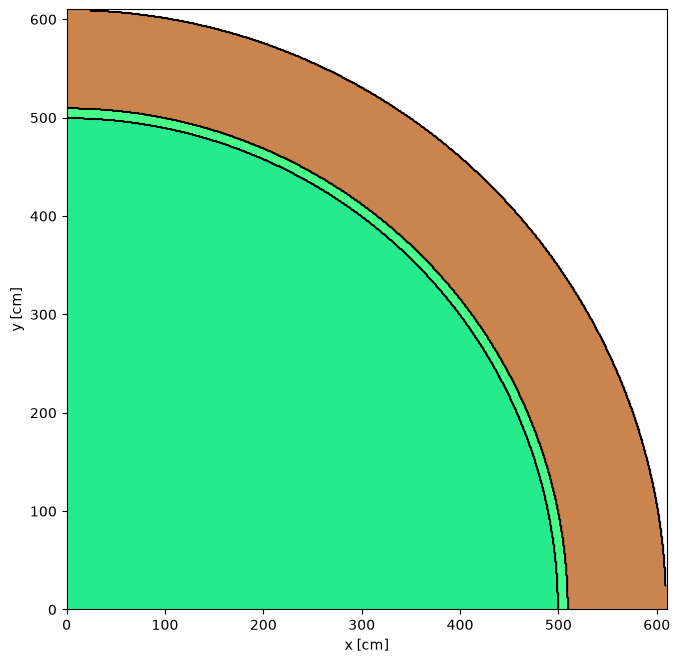

In [2]:
# Load the model saved by 3_0, without rebuilding its materials,
# geometry, source, settings, or tallies.
openmc_model = openmc.Model.from_model_xml('model.xml')

R = 610

ax = openmc_model.plot(
    basis='xy',
    origin=(R / 2, R / 2, 0),
    width=(R, R),
    outline=True,
    pixels=(600, 600),
)

## 2. Restart / continue

OpenMC's restart capability is similar to MCNP's `CONTINUE`. It
resumes from a saved statepoint and retains the accumulated tally
statistics.

The run in `3_0_tritium_breeding_and_neutron_fluence_maps.ipynb`
stopped when its 0.3% relative-error criterion was satisfied. Here,
we tighten the threshold to 0.2% and restart from the saved statepoint.
OpenMC continues until the stricter criterion is met or the maximum
batch count is reached.

In [3]:
# Tighten the existing relative-error convergence trigger to 0.2%.
for tally in openmc_model.tallies:
    for trigger in tally.triggers:
        if trigger.trigger_type == 'rel_err':
            trigger.threshold = 0.002

In [4]:
dir_cont = Path('output_1')
dir_cont.mkdir(parents=True, exist_ok=True)

# Keep the seed and use the tighter convergence trigger. Increasing 
# batches raises the minimum batch count, so the continued run 
# transports additional histories before checking convergence again.
openmc_model.settings.batches += 10
openmc_model.run(
    cwd=dir_cont,
    restart_file='../output_0/statepoint.015.h5',
)

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

PosixPath('/Users/marychin/gitlabcode/power/openmc-workbench/3_run/output_1/statepoint.025.h5')

## 3. Run again with `apply_tally_results=True`

Use a different seed for an independent run. The tightened trigger
and increased minimum batch count from section 2 remain in effect.
OpenMC still writes a statepoint. The tally results are saved in the
statepoint file and also loaded into openmc_model through 
apply_tally_results=True.

In [5]:
output_dir = Path('output_2')
output_dir.mkdir(exist_ok=True)

openmc_model.settings.seed = (openmc_model.settings.seed or 1) + 1
openmc_model.run(apply_tally_results=True, cwd=output_dir)

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

PosixPath('/Users/marychin/gitlabcode/power/openmc-workbench/3_run/output_2/statepoint.035.h5')

## 4. Retrieve tallies without opening a `StatePoint`

In [6]:
openmc_model.tallies

[Tally
 	ID             =	1
 	Name           =	(n,Xt)
 	Filters        =	CellFilter
 	Nuclides       =	Pb204 Pb206 Pb207 Pb208 Li6 Li7 total
 	Scores         =	['(n,Xt)']
 	Estimator      =	None
 	Multiply dens. =	True,
 Tally
 	ID             =	2
 	Name           =	(n,Xt)_convergence
 	Filters        =	CellFilter
 	Nuclides       =	total
 	Scores         =	['(n,Xt)']
 	Estimator      =	None
 	Multiply dens. =	True,
 Tally
 	ID             =	3
 	Name           =	fluence_n_Xt_r_E
 	Filters        =	MeshFilter, EnergyFilter
 	Nuclides       =	total
 	Scores         =	['flux', '(n,Xt)']
 	Estimator      =	None
 	Multiply dens. =	True,
 Tally
 	ID             =	4
 	Name           =	fluence_n_Xt_r
 	Filters        =	MeshFilter, EnergyFilter
 	Nuclides       =	total
 	Scores         =	['flux', '(n,Xt)']
 	Estimator      =	None
 	Multiply dens. =	True]

In [7]:
tallies = {t.name: t for t in openmc_model.tallies}

tally_n_Xt = tallies['(n,Xt)']
tally_map = tallies['fluence_n_Xt_r_E']
tally_r = tallies['fluence_n_Xt_r']

## 5. Post-process

We can now proceed to the tally analysis in section 8 of
`3_0_tritium_breeding_and_neutron_fluence_maps.ipynb`, without
opening the statepoint explicitly. Only the first two cells are
repeated here.

In [8]:
tally_n_Xt

Tally
	ID             =	1
	Name           =	(n,Xt)
	Filters        =	CellFilter
	Nuclides       =	Pb204 Pb206 Pb207 Pb208 Li6 Li7 total
	Scores         =	['(n,Xt)']
	Estimator      =	None
	Multiply dens. =	True

In [9]:
df_n_Xt = tally_n_Xt.get_pandas_dataframe()
df_n_Xt['rel_err'] = df_n_Xt['std. dev.'] / df_n_Xt['mean'].abs()
df_n_Xt.sort_values('mean', ascending=False)

,cell,nuclide,score,mean,std. dev.,rel_err
6,3,total,"(n,Xt)",1.023083e+00,1.832374e-03,0.001791
4,3,Li6,"(n,Xt)",1.019484e+00,1.827239e-03,0.001792
5,3,Li7,"(n,Xt)",3.598986e-03,1.478524e-05,0.004108
3,3,Pb208,"(n,Xt)",7.221961e-08,3.163682e-10,0.004381
2,3,Pb207,"(n,Xt)",2.364427e-08,1.035763e-10,0.004381
0,3,Pb204,"(n,Xt)",1.765201e-08,7.741047e-11,0.004385
1,3,Pb206,"(n,Xt)",0.000000e+00,0.000000e+00,NaN
